# QR2 filter kappas

## Top-left filter
λ/2 resonator coupled to the feedline through an interdigitated capacitor (Q3D, `fcap11`, solved at 10 GHz).

- `cap_body_0` = top pad → resonator
- `cap_body_1` = bottom pad → feedline

Same models as `kappa_calculations.ipynb` (SQuADDS, https://arxiv.org/pdf/2312.13483).
The resonator is designed somewhere in 11–12.5 GHz, so kappa is swept over that band.

## Reference equations

**Resonator equivalent capacitance** ($m=2$ for $\lambda/2$, $m=4$ for $\lambda/4$):

$$C_r = \frac{\pi}{m\,\omega_r Z_0}$$

### Göppl model
Treats the coupler as a single series capacitor $C_c$ (here $C_c = C_{rf}$) and ignores loading of the resonator:

$$Q = \frac{C_r}{\omega_r Z_0 C_c^2}, \qquad \kappa_{\rm Goppl} = \frac{\omega_r}{Q} = \frac{\omega_r^2 Z_0 C_c^2}{C_r}$$

### Coupled model
Includes the resonator-to-feedline capacitance $C_{rf}$ and coupler-pad-to-ground capacitance $C_{cg}$, which load the resonator and shift it down from its uncoupled frequency $\omega'$:

$$\omega_r = \sqrt{\frac{C_r}{C_r + C_{rf} + C_{cg}}}\;\omega'$$

$$\kappa = \frac{1}{2}\, Z_0\, \omega_r^2\, \frac{C_{rf}^2}{C_r + C_{rf} + C_{cg}}$$

All $\kappa$ values below are reported as $\kappa/2\pi$.

In [74]:
import numpy as np

In [75]:
# Q3D Maxwell capacitance matrix (fF), fcap11 @ 10 GHz
#                     cap_body_0  cap_body_1  ground_main_plane
C_matrix = np.array([[ 58.24425, -28.25856, -29.60590],
                     [-28.25856,  58.26332, -29.60016],
                     [-29.60590, -29.60016,  89.68905]])

Crf_fF = -C_matrix[0, 1]   # resonator pad <-> feedline pad
Ccg_fF = -C_matrix[0, 2]   # resonator pad <-> ground

m = 2       # lambda/2
Z_0 = 50    # Ohms
freqs_GHz = np.array([11.0, 11.5, 12.0, 12.5])

In [76]:
def calc_cr(m, f_GHz, Z_0):
    omega_r = 2 * np.pi * f_GHz * 1e9   # rad/s
    return np.pi / (m * omega_r * Z_0)   # Farads

def calc_kappa_goppl_kHz(f_GHz, m, Cc_fF, Z_0):
    omega_r = 2 * np.pi * f_GHz * 1e9   # rad/s
    Cc = Cc_fF * 1e-15                   # Farads
    Q = calc_cr(m, f_GHz, Z_0) / (omega_r * Z_0 * Cc**2)
    return omega_r / Q / (2 * np.pi * 1e3)  # kHz

def calc_kappa_coupled(f_GHz, m, Crf_fF, Ccg_fF, Z_0):
    omega_prime = 2 * np.pi * f_GHz * 1e9            # uncoupled, rad/s
    Cr = calc_cr(m, f_GHz, Z_0)
    C_tot = Cr + (Crf_fF + Ccg_fF) * 1e-15
    omega_r = np.sqrt(Cr / C_tot) * omega_prime      # loaded, rad/s
    kappa = 0.5 * Z_0 * omega_r**2 * (Crf_fF * 1e-15)**2 / C_tot
    return omega_r / (2 * np.pi * 1e9), kappa / (2 * np.pi * 1e3)  # GHz, kHz

In [77]:
print(f"Crf = {Crf_fF:.3f} fF, Ccg = {Ccg_fF:.3f} fF\n")
print(f"{'f (GHz)':>8} {'Cr (fF)':>9} {'f_loaded':>9} {'k/2pi coupled':>15} {'k/2pi Goppl':>13}")
for f in freqs_GHz:
    Cr = calc_cr(m, f, Z_0) * 1e15
    fl, k_c = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF, Z_0)
    k_g = calc_kappa_goppl_kHz(f, m, Crf_fF, Z_0)
    print(f"{f:8.2f} {Cr:9.2f} {fl:9.4f} {k_c/1e3:11.3f} MHz {k_g/1e3:9.3f} MHz")

Crf = 28.259 fF, Ccg = 29.606 fF

 f (GHz)   Cr (fF)  f_loaded   k/2pi coupled   k/2pi Goppl
   11.00    454.55   10.3603      26.275 MHz    66.782 MHz
   11.50    434.78   10.8035      29.718 MHz    76.309 MHz
   12.00    416.67   11.2446      33.423 MHz    86.701 MHz
   12.50    400.00   11.6835      37.396 MHz    97.996 MHz


### Top-left filter: effect of the dissipator coupling
Q3D `diss1`, solved at 6 GHz (fF). `cross_1_diss1` is the dissipator transmon; `south_cpw_diss1` is the filter stub that couples to it.

The dissipator is a transmon ($C_\Sigma = 77.9$ fF, $E_J/2\pi = 64.54$ GHz, $E_C/2\pi = 248.7$ MHz, $f_{ge} \approx 11.08$ GHz). It sits inside the filter band, so the dispersive columns can break down; the eigenmode table below them is the exact two-mode check. Its effect on the filter:

- **Capacitive loading:** $C_d$ adds to the resonator's total capacitance, $C_\Sigma^{\rm filter} = C_r + C_{rf} + C_{cg} + C_d$.
- **Coupling** (stub assumed at a voltage antinode, so this is an upper bound): $g = \frac{1}{2}\frac{C_d}{\sqrt{C_q C_r}}\sqrt{\omega_q \omega_r}$
- **Dispersive pull on the filter:** $\delta\omega_r \approx g^2/\Delta$, with $\Delta = \omega_r - \omega_q$
- **Linewidth inherited from the dissipator:** $\kappa_{\rm induced} \approx (g/\Delta)^2 \gamma_d$, where $\gamma_d$ is the dissipator's own (non-filter) decay rate
- **Reverse direction, Purcell decay of the dissipator through the filter:** $\gamma_{\rm Purcell} \approx (g/\Delta)^2 \kappa$

In [78]:
# Q3D Maxwell capacitance matrix (fF), diss1 @ 6 GHz
#  order: cross_0_diss1, cross_1_diss1, cross_logic1, ground_main_plane, south_cpw_diss1
C_diss = np.array([[179.36079, -10.01493,  -8.43706, -160.16643, -0.00978],
                   [-10.01493,  77.92045,  -0.77122,  -65.56098, -0.83757],
                   [ -8.43706,  -0.77122,  91.49216,  -81.14572, -0.02198],
                   [-160.16643, -65.56098, -81.14572, 366.57241, -8.31961],
                   [ -0.00978,  -0.83757,  -0.02198,   -8.31961,  9.22789]])

Cd_fF  = -C_diss[1, 4]   # dissipator cross <-> filter stub
Cq_fF  = 77.9            # dissipator C_sigma, fF
fq_GHz = 11.0824         # dissipator f_ge
gamma_d_kHz = 1 / (2 * np.pi * 5e-6) / 1e3    # dissipator T1 = 5 us

# top-left filter coupler (fcap11)
Crf_fF, Ccg_fF = 28.25856, 29.60590

print(f"C_d = {Cd_fF:.3f} fF, gamma_d/2pi = {gamma_d_kHz:.2f} kHz\n")
print(f"{'f (GHz)':>8} {'f_loaded':>9} {'g/2pi':>9} {'Delta':>8} {'pull':>9} "
      f"{'k (no diss)':>12} {'k (with C_d)':>13} {'k induced':>10} {'Purcell':>10}")
for f in freqs_GHz:
    fl0, k0 = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF, Z_0)
    fl, k = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF + Cd_fF, Z_0)   # C_d loads like C_cg
    Cr_fF = calc_cr(m, fl, Z_0) * 1e15
    g_MHz = 0.5 * Cd_fF / np.sqrt(Cq_fF * Cr_fF) * np.sqrt(fq_GHz * fl) * 1e3
    Delta_MHz = (fl - fq_GHz) * 1e3
    ratio = (g_MHz / Delta_MHz)**2
    print(f"{f:8.2f} {fl:9.4f} {g_MHz:6.2f} MHz {Delta_MHz/1e3:5.2f} GHz {g_MHz**2/Delta_MHz*1e3:6.1f} kHz "
          f"{k0/1e3:8.3f} MHz {k/1e3:9.3f} MHz {ratio*gamma_d_kHz*1e3:6.3f} Hz {ratio*k:7.2f} kHz")

# Dispersive formulas need |g/Delta| << 1. Exact check: diagonalize the damped
# two-mode Hamiltonian; each eigenvalue is (frequency - i*linewidth/2).
print(f"\n{'f (GHz)':>8} {'g/Delta':>8} {'filter-like f':>14} {'k':>10} {'diss-like f':>12} {'gamma':>11}")
for f in freqs_GHz:
    fl, k = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF + Cd_fF, Z_0)
    Cr_fF = calc_cr(m, fl, Z_0) * 1e15
    g_MHz = 0.5 * Cd_fF / np.sqrt(Cq_fF * Cr_fF) * np.sqrt(fq_GHz * fl) * 1e3
    H = np.array([[fl * 1e3 - 0.5j * k / 1e3, g_MHz],
                  [g_MHz, fq_GHz * 1e3 - 0.5j * gamma_d_kHz / 1e3]])   # MHz
    ev, vecs = np.linalg.eig(H)
    i_f = np.argmax(np.abs(vecs[0]))    # mode with most filter weight
    i_q = 1 - i_f
    print(f"{f:8.2f} {g_MHz/((fl - fq_GHz)*1e3):8.3f} {ev[i_f].real/1e3:10.4f} GHz {-2*ev[i_f].imag:6.2f} MHz "
          f"{ev[i_q].real/1e3:8.4f} GHz {-2*ev[i_q].imag*1e3:7.1f} kHz")

C_d = 0.838 fF, gamma_d/2pi = 31.83 kHz

 f (GHz)  f_loaded     g/2pi    Delta      pull  k (no diss)  k (with C_d)  k induced    Purcell
   11.00   10.3518  23.12 MHz -0.73 GHz -732.0 kHz   26.275 MHz    26.190 MHz 31.893 Hz   26.24 kHz
   11.50   10.7944  24.11 MHz -0.29 GHz -2018.6 kHz   29.718 MHz    29.617 MHz 223.081 Hz  207.56 kHz
   12.00   11.2347  25.10 MHz  0.15 GHz 4136.3 kHz   33.423 MHz    33.305 MHz 864.666 Hz  904.71 kHz
   12.50   11.6728  26.08 MHz  0.59 GHz 1151.6 kHz   37.396 MHz    37.260 MHz 62.091 Hz   72.68 kHz

 f (GHz)  g/Delta  filter-like f          k  diss-like f       gamma
   11.00   -0.032    10.3511 GHz  26.16 MHz  11.0831 GHz    58.0 kHz
   11.50   -0.084    10.7924 GHz  29.41 MHz  11.0844 GHz   234.4 kHz
   12.00    0.165    11.2387 GHz  32.48 MHz  11.0784 GHz   859.8 kHz
   12.50    0.044    11.6739 GHz  37.19 MHz  11.0813 GHz   104.0 kHz


#### Dissipator tuning: effect on the filter
The dissipator is SQUID-tunable and the quoted $f_{ge}$ is its maximum (zero flux), so it can only tune *down*. Sweep $f_{ge}$ from 9.5 GHz up to $f_{ge}^{
m max}$ and track the filter-like mode. Any filter whose loaded frequency is below $f_{ge}^{
m max}$ can be crossed while tuning; one above it never is. Three quantities matter for the filter:

- **Frequency pull** of the filter (dissipator in $|g\rangle$), from the exact two-mode eigenvalues, relative to the filter with $C_d$ loading but no coupling.
- **Filter linewidth** $\kappa$ of the filter-like mode, from the same eigenvalues.
- **Dispersive shift** (transmon, Koch et al. 2007), with $\Delta = \omega_{ge} - \omega_r$ and $g_{12} = \sqrt{2}\,g$:

$$\chi_{01} = \frac{g^2}{\Delta}, \quad \chi_{12} = \frac{2g^2}{\Delta - E_C}, \quad 2\chi = \omega_r^{|e\rangle} - \omega_r^{|g\rangle} = 2\chi_{01} - \chi_{12}$$

$2\chi/\kappa$ says whether the filter can tell which state the dissipator is in: if $|2\chi| \ll \kappa$ the dissipator state is invisible in the filter response. $2\chi$ is only valid when both $|g/\Delta|$ and $|\sqrt{2}g/(\Delta - E_C)|$ are $\lesssim 0.1$ (filter far from both the $ge$ and $ef$ transitions), so other points are masked; near those transitions the filter and dissipator hybridize and the pull/$\kappa$ panels are the exact answer. The dashed line marks $f_{ge}^{
m max}$; the tables give the values with the dissipator parked there.

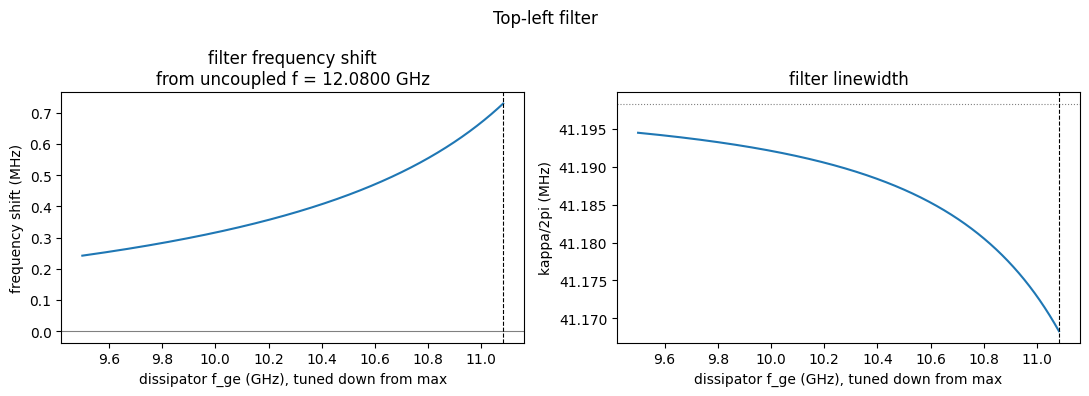

Top-left filter: loaded target 12.0800 GHz (bare 12.9670 GHz)
  at f_ge,max = 11.0824 GHz: filter f = 12.0807 GHz (shift +0.73 MHz), kappa/2pi = 41.17 MHz (uncoupled 41.20 MHz)



In [79]:
import matplotlib.pyplot as plt

def bare_from_loaded(f_loaded_GHz, Crf_fF, Ccg_fF):
    """Bare (uncoupled) frequency whose loaded frequency, from calc_kappa_coupled, equals f_loaded_GHz."""
    lo, hi = f_loaded_GHz, 1.3 * f_loaded_GHz
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        fl, _ = calc_kappa_coupled(mid, m, Crf_fF, Ccg_fF, Z_0)
        if fl < f_loaded_GHz:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def filter_vs_dissipator(Crf_fF, Ccg_fF, Cd_fF, Cq_fF, fq_design_GHz, gamma_d_kHz, label,
                         f_loaded_GHz, fq_sweep_GHz=None):
    # f_loaded_GHz: measured (or driven-modal) loaded frequency of this filter, including the dissipator
    # loading Cd. The model input is the bare frequency that reproduces it.
    # Reference frequency fl is the filter with Cd loading but no coupling to the dissipator.
    f_bare = bare_from_loaded(f_loaded_GHz, Crf_fF, Ccg_fF + Cd_fF)
    fl, k = calc_kappa_coupled(f_bare, m, Crf_fF, Ccg_fF + Cd_fF, Z_0)   # GHz, kHz
    k_MHz = k / 1e3
    Cr_fF = calc_cr(m, fl, Z_0) * 1e15
    if fq_sweep_GHz is None:
        fq_sweep_GHz = np.linspace(9.5, fq_design_GHz, 1201)   # f_ge given is the max; SQUID tunes down only

    def solve(fq):
        g_MHz = 0.5 * Cd_fF / np.sqrt(Cq_fF * Cr_fF) * np.sqrt(fq * fl) * 1e3
        H = np.array([[fl * 1e3 - 0.5j * k_MHz, g_MHz],
                      [g_MHz, fq * 1e3 - 0.5j * gamma_d_kHz / 1e3]])   # MHz
        ev, vecs = np.linalg.eig(H)
        i_f = np.argmax(np.abs(vecs[0]))                               # filter-like eigenmode
        shift_MHz = ev[i_f].real - fl * 1e3                            # frequency shift from fl
        kappa_MHz = -2 * ev[i_f].imag                                  # filter linewidth kappa/2pi
        return shift_MHz, kappa_MHz

    res = np.array([solve(fq) for fq in fq_sweep_GHz]).real
    shift, kap = res.T

    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    axs[0].plot(fq_sweep_GHz, shift)
    axs[0].axhline(0, color="gray", lw=0.8)
    axs[0].set_title(f"filter frequency shift\nfrom uncoupled f = {fl:.4f} GHz")
    axs[0].set_ylabel("frequency shift (MHz)")
    axs[1].plot(fq_sweep_GHz, kap)
    axs[1].axhline(k_MHz, color="gray", lw=0.8, ls=":")
    axs[1].set_title("filter linewidth")
    axs[1].set_ylabel("kappa/2pi (MHz)")
    for ax in axs:
        ax.axvline(fq_design_GHz, color="k", ls="--", lw=0.8)
        ax.set_xlabel("dissipator f_ge (GHz), tuned down from max")
    fig.suptitle(label)
    fig.tight_layout()
    plt.show()

    s_max, k_max = solve(fq_design_GHz)
    print(f"{label}: loaded target {f_loaded_GHz:.4f} GHz (bare {f_bare:.4f} GHz)")
    print(f"  at f_ge,max = {fq_design_GHz:.4f} GHz: filter f = {fl + s_max/1e3:.4f} GHz "
          f"(shift {s_max:+.2f} MHz), kappa/2pi = {k_max:.2f} MHz (uncoupled {k_MHz:.2f} MHz)")
    print()

# top-left: measured mode 12.08 GHz
filter_vs_dissipator(28.25856, 29.60590, 0.83757, 77.9, 11.0824,
                     1 / (2 * np.pi * 5e-6) / 1e3, "Top-left filter", 12.08)

In [80]:
def fge_vs_current(I_uA, EJmax_GHz, EC_MHz, I_period_uA):
    """Dissipator f_ge vs coil current for a symmetric SQUID: E_J = E_Jmax |cos(pi Phi/Phi0)|, Phi/Phi0 = I/I_period."""
    EJ = EJmax_GHz * np.abs(np.cos(np.pi * I_uA / I_period_uA))
    EC = EC_MHz / 1e3
    return np.sqrt(8 * EJ * EC) - EC   # GHz

def filter_flux_tuning(Crf_fF, Ccg_fF, Cd_fF, Cq_fF, EC_MHz, EJmax_GHz, fq_max_GHz, gamma_d_kHz,
                       I_period_uA, f_loaded_GHz, label, kappa_ext_MHz=None, kappa_int_MHz=0.0,
                       fq_valid_GHz=9.5, span_MHz=300):
    # Filter mode frequency vs flux quanta, and a hanger-type S21 trace at the sweet spot (I = 0).
    # kappa_ext_MHz defaults to the model's external linewidth; kappa_int_MHz is internal loss (not in the model).
    f_bare = bare_from_loaded(f_loaded_GHz, Crf_fF, Ccg_fF + Cd_fF)
    fl, k = calc_kappa_coupled(f_bare, m, Crf_fF, Ccg_fF + Cd_fF, Z_0)
    if kappa_ext_MHz is None:
        kappa_ext_MHz = k / 1e3
    Cr_fF = calc_cr(m, fl, Z_0) * 1e15

    I = np.linspace(0, I_period_uA, 401)
    fq = fge_vs_current(I, EJmax_GHz, EC_MHz, I_period_uA)
    f_mode = np.full_like(I, np.nan)
    for j, fqj in enumerate(fq):
        if fqj < fq_valid_GHz:          # transmon formula is only used where the dissipator is in the analyzed range
            continue
        g_MHz = 0.5 * Cd_fF / np.sqrt(Cq_fF * Cr_fF) * np.sqrt(fqj * fl) * 1e3
        H = np.array([[fl * 1e3 - 0.5j * kappa_ext_MHz, g_MHz],
                      [g_MHz, fqj * 1e3 - 0.5j * gamma_d_kHz / 1e3]])   # MHz
        ev, vecs = np.linalg.eig(H)
        f_mode[j] = ev[np.argmax(np.abs(vecs[0]))].real / 1e3          # filter-like mode, GHz

    # VNA hanger response at the sweet spot (I = 0, dissipator at its maximum)
    f_r = f_mode[0]
    kappa_tot = (kappa_ext_MHz + kappa_int_MHz) / 1e3                  # GHz
    f_axis = np.linspace(f_r - span_MHz / 2e3, f_r + span_MHz / 2e3, 2001)
    S21 = 1 - (kappa_ext_MHz / 1e3 / 2) / (1j * (f_axis - f_r) + kappa_tot / 2)
    logmag = 20 * np.log10(np.abs(S21))

    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    axs[0].plot(I / I_period_uA, f_mode, color="C0")
    axs[0].set_xlabel("flux quanta, Phi/Phi0 = I / I_period")
    axs[0].set_ylabel("filter mode frequency (GHz)")
    axs[0].set_title("filter mode vs flux")
    axs[1].plot((f_axis - f_r) * 1e3, np.maximum(logmag, -60), color="C0")
    axs[1].set_xlabel("frequency offset from f_r (MHz)")
    axs[1].set_ylabel("|S21| (dB)")
    axs[1].set_title(f"simulated S21 at I = 0, kappa/2pi = {kappa_tot*1e3:.1f} MHz")
    fig.suptitle(label)
    fig.tight_layout()
    plt.show()

    valid = ~np.isnan(f_mode)
    print(f"{label}: loaded target {f_loaded_GHz:.4f} GHz, period {I_period_uA} uA")
    print(f"  mode at I = 0: {f_r:.4f} GHz; tuning over the valid range: "
          f"{(np.nanmax(f_mode) - np.nanmin(f_mode)) * 1e3:.2f} MHz (min {np.nanmin(f_mode):.4f}, max {np.nanmax(f_mode):.4f} GHz)")
    print(f"  kappa/2pi: external {kappa_ext_MHz:.2f} MHz, internal {kappa_int_MHz:.2f} MHz")
    print()


## Top-right filter
Q3D, `fcap12`, solved at 10 GHz (fF). `cap_body_0` = top pad → resonator, `cap_body_1` = bottom pad → feedline.

In [81]:
# Q3D Maxwell capacitance matrix (fF), fcap12 @ 10 GHz
#                     cap_body_0  cap_body_1  ground_main_plane
C_matrix = np.array([[ 69.07193, -32.09076, -36.51643],
                     [-32.09076,  58.21678, -25.74256],
                     [-36.51643, -25.74256,  92.79998]])

Crf_fF = -C_matrix[0, 1]   # resonator pad <-> feedline pad
Ccg_fF = -C_matrix[0, 2]   # resonator pad <-> ground

In [82]:
print(f"Crf = {Crf_fF:.3f} fF, Ccg = {Ccg_fF:.3f} fF\n")
print(f"{'f (GHz)':>8} {'Cr (fF)':>9} {'f_loaded':>9} {'k/2pi coupled':>15} {'k/2pi Goppl':>13}")
for f in freqs_GHz:
    Cr = calc_cr(m, f, Z_0) * 1e15
    fl, k_c = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF, Z_0)
    k_g = calc_kappa_goppl_kHz(f, m, Crf_fF, Z_0)
    print(f"{f:8.2f} {Cr:9.2f} {fl:9.4f} {k_c/1e3:11.3f} MHz {k_g/1e3:9.3f} MHz")

Crf = 32.091 fF, Ccg = 36.516 fF

 f (GHz)   Cr (fF)  f_loaded   k/2pi coupled   k/2pi Goppl
   11.00    454.55   10.2534      32.508 MHz    86.123 MHz
   11.50    434.78   10.6876      36.706 MHz    98.409 MHz
   12.00    416.67   11.1194      41.215 MHz   111.811 MHz
   12.50    400.00   11.5488      46.041 MHz   126.378 MHz


### Top-right filter: effect of the dissipator coupling
Q3D `diss2`, solved at 6.0177 GHz (fF). `cross_0_diss2` is the coupling claw, `cross_1_diss2` is the dissipator transmon, `south_cpw_diss2` is the filter stub. Same equations as the top-left dissipator section.

This dissipator: $C_\Sigma = 75.33$ fF, $E_J/2\pi = 69.51$ GHz, $E_C/2\pi = 257.1$ MHz, $f_{ge} \approx 11.70$ GHz. $T_1$ assumed 5 µs, same as top-left.

It sits inside the filter band, so $g/\Delta$ is not small at the high end of the sweep and the dispersive columns break down there; use the eigenmode table instead.

In [83]:
# Q3D Maxwell capacitance matrix (fF), diss2 @ 6.0177 GHz
#  order: cross_0_diss2, cross_1_diss2, cross_logic2, ground_main_plane, south_cpw_diss2
C_diss = np.array([[211.88645, -10.10434,  -5.24436, -195.86724, -0.00978],
                   [-10.10434,  75.33685,  -0.52705,  -63.05360, -0.91066],
                   [ -5.24436,  -0.52705,  95.63077,  -88.71337, -0.01677],
                   [-195.86724, -63.05360, -88.71337, 407.32229, -8.25995],
                   [ -0.00978,  -0.91066,  -0.01677,   -8.25995,  9.22254]])

Cd_fF  = -C_diss[1, 4]   # dissipator cross <-> filter stub
Cq_fF  = 75.33           # dissipator C_sigma, fF
fq_GHz = 11.7006         # dissipator f_ge
gamma_d_kHz = 1 / (2 * np.pi * 5e-6) / 1e3    # dissipator T1 = 5 us

# top-right filter coupler (fcap12)
Crf_fF, Ccg_fF = 32.09076, 36.51643

print(f"C_d = {Cd_fF:.3f} fF, gamma_d/2pi = {gamma_d_kHz:.2f} kHz\n")
print(f"{'f (GHz)':>8} {'f_loaded':>9} {'g/2pi':>9} {'Delta':>8} {'pull':>9} "
      f"{'k (no diss)':>12} {'k (with C_d)':>13} {'k induced':>10} {'Purcell':>10}")
for f in freqs_GHz:
    fl0, k0 = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF, Z_0)
    fl, k = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF + Cd_fF, Z_0)   # C_d loads like C_cg
    Cr_fF = calc_cr(m, fl, Z_0) * 1e15
    g_MHz = 0.5 * Cd_fF / np.sqrt(Cq_fF * Cr_fF) * np.sqrt(fq_GHz * fl) * 1e3
    Delta_MHz = (fl - fq_GHz) * 1e3
    ratio = (g_MHz / Delta_MHz)**2
    print(f"{f:8.2f} {fl:9.4f} {g_MHz:6.2f} MHz {Delta_MHz/1e3:5.2f} GHz {g_MHz**2/Delta_MHz*1e3:6.1f} kHz "
          f"{k0/1e3:8.3f} MHz {k/1e3:9.3f} MHz {ratio*gamma_d_kHz*1e3:6.3f} Hz {ratio*k:7.2f} kHz")

# Dispersive formulas need |g/Delta| << 1. Exact check: diagonalize the damped
# two-mode Hamiltonian; each eigenvalue is (frequency - i*linewidth/2).
print(f"\n{'f (GHz)':>8} {'g/Delta':>8} {'filter-like f':>14} {'k':>10} {'diss-like f':>12} {'gamma':>11}")
for f in freqs_GHz:
    fl, k = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF + Cd_fF, Z_0)
    Cr_fF = calc_cr(m, fl, Z_0) * 1e15
    g_MHz = 0.5 * Cd_fF / np.sqrt(Cq_fF * Cr_fF) * np.sqrt(fq_GHz * fl) * 1e3
    H = np.array([[fl * 1e3 - 0.5j * k / 1e3, g_MHz],
                  [g_MHz, fq_GHz * 1e3 - 0.5j * gamma_d_kHz / 1e3]])   # MHz
    ev, vecs = np.linalg.eig(H)
    i_f = np.argmax(np.abs(vecs[0]))    # mode with most filter weight
    i_q = 1 - i_f
    print(f"{f:8.2f} {g_MHz/((fl - fq_GHz)*1e3):8.3f} {ev[i_f].real/1e3:10.4f} GHz {-2*ev[i_f].imag:6.2f} MHz "
          f"{ev[i_q].real/1e3:8.4f} GHz {-2*ev[i_q].imag*1e3:7.1f} kHz")

C_d = 0.911 fF, gamma_d/2pi = 31.83 kHz

 f (GHz)  f_loaded     g/2pi    Delta      pull  k (no diss)  k (with C_d)  k induced    Purcell
   11.00   10.2445  26.00 MHz -1.46 GHz -464.2 kHz   32.508 MHz    32.395 MHz 10.147 Hz   10.33 kHz
   11.50   10.6780  27.10 MHz -1.02 GHz -718.1 kHz   36.706 MHz    36.574 MHz 22.352 Hz   25.68 kHz
   12.00   11.1090  28.19 MHz -0.59 GHz -1343.5 kHz   41.215 MHz    41.061 MHz 72.289 Hz   93.25 kHz
   12.50   11.5376  29.28 MHz -0.16 GHz -5258.4 kHz   46.041 MHz    45.862 MHz 1026.620 Hz 1479.16 kHz

 f (GHz)  g/Delta  filter-like f          k  diss-like f       gamma
   11.00   -0.018    10.2440 GHz  32.38 MHz  11.7011 GHz    42.1 kHz
   11.50   -0.026    10.6773 GHz  36.55 MHz  11.7013 GHz    57.4 kHz
   12.00   -0.048    11.1077 GHz  40.97 MHz  11.7019 GHz   124.3 kHz
   12.50   -0.180    11.5325 GHz  44.53 MHz  11.7056 GHz  1359.5 kHz


#### Dissipator tuning: effect on the filter
Same sweep as the top-left section.

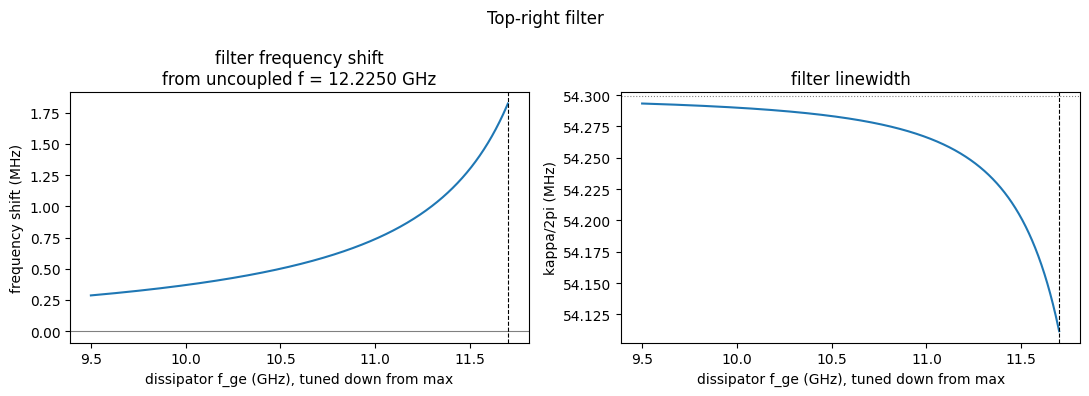

Top-right filter: loaded target 12.2250 GHz (bare 13.3080 GHz)
  at f_ge,max = 11.7006 GHz: filter f = 12.2268 GHz (shift +1.82 MHz), kappa/2pi = 54.11 MHz (uncoupled 54.30 MHz)



In [84]:
# top-right: no measured mode yet, driven-modal 12.225 GHz
filter_vs_dissipator(32.09076, 36.51643, 0.91066, 75.33, 11.7006,
                     1 / (2 * np.pi * 5e-6) / 1e3, "Top-right filter", 12.225)

## Bottom-left filter
Q3D, `fcap21`, solved at 10 GHz (fF). Orientation is flipped here: `cap_body_0` = bottom pad → resonator, `cap_body_1` = top pad → feedline.

In [85]:
# Q3D Maxwell capacitance matrix (fF), fcap21 @ 10 GHz
#                     cap_body_0  cap_body_1  ground_main_plane
C_matrix = np.array([[ 71.08224, -37.35897, -33.25686],
                     [-37.35897,  71.08416, -33.26112],
                     [-33.25686, -33.26112,  97.59395]])

Crf_fF = -C_matrix[0, 1]   # resonator pad (bottom) <-> feedline pad (top)
Ccg_fF = -C_matrix[0, 2]   # resonator pad (bottom) <-> ground

In [86]:
print(f"Crf = {Crf_fF:.3f} fF, Ccg = {Ccg_fF:.3f} fF\n")
print(f"{'f (GHz)':>8} {'Cr (fF)':>9} {'f_loaded':>9} {'k/2pi coupled':>15} {'k/2pi Goppl':>13}")
for f in freqs_GHz:
    Cr = calc_cr(m, f, Z_0) * 1e15
    fl, k_c = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF, Z_0)
    k_g = calc_kappa_goppl_kHz(f, m, Crf_fF, Z_0)
    print(f"{f:8.2f} {Cr:9.2f} {fl:9.4f} {k_c/1e3:11.3f} MHz {k_g/1e3:9.3f} MHz")

Crf = 37.359 fF, Ccg = 33.257 fF

 f (GHz)   Cr (fF)  f_loaded   k/2pi coupled   k/2pi Goppl
   11.00    454.55   10.2338      43.721 MHz   116.721 MHz
   11.50    434.78   10.6664      49.353 MHz   133.372 MHz
   12.00    416.67   11.0965      55.399 MHz   151.535 MHz
   12.50    400.00   11.5241      61.867 MHz   171.277 MHz


### Bottom-left filter: effect of the dissipator coupling
Q3D `diss3` full layout (dissipator + claw + logic qubit + filter stub), solved at 6.141 GHz (fF). Labels are flipped relative to `diss1`/`diss2`: `cross_0_diss3` is the dissipator transmon, `cross_1_diss3` is the coupling claw, `south_cpw_diss3` is the filter stub. Same equations as the top-left dissipator section.

This dissipator: $C_\Sigma = 75.9$ fF, $E_J/2\pi = 64.54$ GHz, $E_C/2\pi = 255.2$ MHz, $f_{ge} \approx 11.22$ GHz. $T_1$ assumed 5 µs, same as top-left.

In [87]:
# Q3D Maxwell capacitance matrix (fF), diss3 @ 6.141 GHz
#  order: cross_0_diss3, cross_1_diss3, cross_logic3, ground_main_plane, south_cpw_diss3
C_diss = np.array([[ 75.94341,  -9.93992,  -0.74677,  -63.85002, -0.76066],
                   [ -9.93992, 201.67816,  -5.12830, -185.84637, -0.01083],
                   [ -0.74677,  -5.12830,  87.40507,  -80.52934, -0.02309],
                   [-63.85002, -185.84637, -80.52934, 388.90818, -8.40107],
                   [ -0.76066,  -0.01083,  -0.02309,   -8.40107,  9.23106]])

Cd_fF  = -C_diss[0, 4]   # dissipator cross (cross_0 here) <-> filter stub
Cq_fF  = 75.9            # dissipator C_sigma, fF
fq_GHz = 11.2242         # dissipator f_ge
gamma_d_kHz = 1 / (2 * np.pi * 5e-6) / 1e3    # dissipator T1 = 5 us

# bottom-left filter coupler (fcap21)
Crf_fF, Ccg_fF = 37.35897, 33.25686

print(f"C_d = {Cd_fF:.3f} fF, gamma_d/2pi = {gamma_d_kHz:.2f} kHz\n")
print(f"{'f (GHz)':>8} {'f_loaded':>9} {'g/2pi':>9} {'Delta':>8} {'pull':>9} "
      f"{'k (no diss)':>12} {'k (with C_d)':>13} {'k induced':>10} {'Purcell':>10}")
for f in freqs_GHz:
    fl0, k0 = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF, Z_0)
    fl, k = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF + Cd_fF, Z_0)   # C_d loads like C_cg
    Cr_fF = calc_cr(m, fl, Z_0) * 1e15
    g_MHz = 0.5 * Cd_fF / np.sqrt(Cq_fF * Cr_fF) * np.sqrt(fq_GHz * fl) * 1e3
    Delta_MHz = (fl - fq_GHz) * 1e3
    ratio = (g_MHz / Delta_MHz)**2
    print(f"{f:8.2f} {fl:9.4f} {g_MHz:6.2f} MHz {Delta_MHz/1e3:5.2f} GHz {g_MHz**2/Delta_MHz*1e3:6.1f} kHz "
          f"{k0/1e3:8.3f} MHz {k/1e3:9.3f} MHz {ratio*gamma_d_kHz*1e3:6.3f} Hz {ratio*k:7.2f} kHz")

# Dispersive formulas need |g/Delta| << 1. Exact check: diagonalize the damped
# two-mode Hamiltonian; each eigenvalue is (frequency - i*linewidth/2).
print(f"\n{'f (GHz)':>8} {'g/Delta':>8} {'filter-like f':>14} {'k':>10} {'diss-like f':>12} {'gamma':>11}")
for f in freqs_GHz:
    fl, k = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF + Cd_fF, Z_0)
    Cr_fF = calc_cr(m, fl, Z_0) * 1e15
    g_MHz = 0.5 * Cd_fF / np.sqrt(Cq_fF * Cr_fF) * np.sqrt(fq_GHz * fl) * 1e3
    H = np.array([[fl * 1e3 - 0.5j * k / 1e3, g_MHz],
                  [g_MHz, fq_GHz * 1e3 - 0.5j * gamma_d_kHz / 1e3]])   # MHz
    ev, vecs = np.linalg.eig(H)
    i_f = np.argmax(np.abs(vecs[0]))    # mode with most filter weight
    i_q = 1 - i_f
    print(f"{f:8.2f} {g_MHz/((fl - fq_GHz)*1e3):8.3f} {ev[i_f].real/1e3:10.4f} GHz {-2*ev[i_f].imag:6.2f} MHz "
          f"{ev[i_q].real/1e3:8.4f} GHz {-2*ev[i_q].imag*1e3:7.1f} kHz")

C_d = 0.761 fF, gamma_d/2pi = 31.83 kHz

 f (GHz)  f_loaded     g/2pi    Delta      pull  k (no diss)  k (with C_d)  k induced    Purcell
   11.00   10.2264  21.15 MHz -1.00 GHz -448.4 kHz   43.721 MHz    43.594 MHz 14.303 Hz   19.59 kHz
   11.50   10.6584  22.05 MHz -0.57 GHz -858.9 kHz   49.353 MHz    49.204 MHz 48.318 Hz   74.69 kHz
   12.00   11.0878  22.93 MHz -0.14 GHz -3856.9 kHz   55.399 MHz    55.226 MHz 900.249 Hz 1561.91 kHz
   12.50   11.5148  23.82 MHz  0.29 GHz 1952.1 kHz   61.867 MHz    61.667 MHz 213.827 Hz  414.25 kHz

 f (GHz)  g/Delta  filter-like f          k  diss-like f       gamma
   11.00   -0.021    10.2259 GHz  43.57 MHz  11.2246 GHz    51.4 kHz
   11.50   -0.039    10.6575 GHz  49.13 MHz  11.2251 GHz   106.0 kHz
   12.00   -0.168    11.0842 GHz  53.83 MHz  11.2278 GHz  1424.3 kHz
   12.50    0.082    11.5167 GHz  61.27 MHz  11.2223 GHz   433.4 kHz


#### Dissipator tuning: effect on the filter
Same sweep as the top-left section.

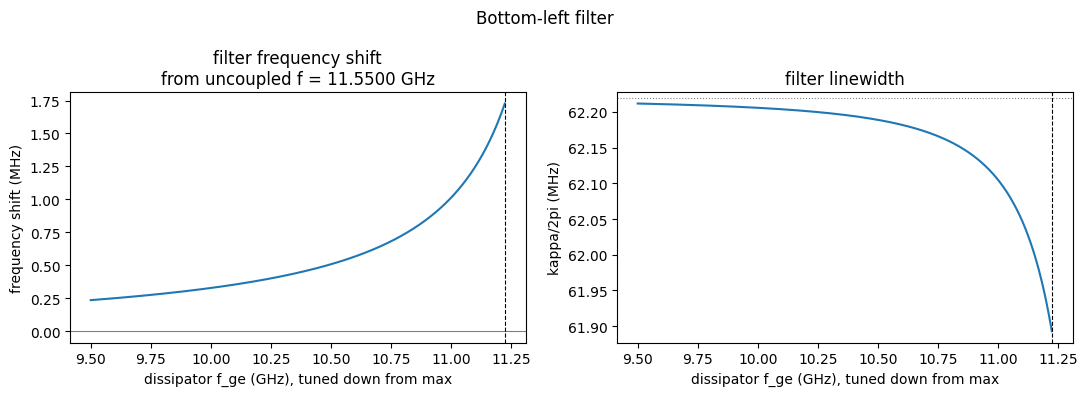

Bottom-left filter: loaded target 11.5500 GHz (bare 12.5414 GHz)
  at f_ge,max = 11.2242 GHz: filter f = 11.5517 GHz (shift +1.73 MHz), kappa/2pi = 61.89 MHz (uncoupled 62.22 MHz)



In [88]:
# bottom-left: measured mode 11.55 GHz
filter_vs_dissipator(37.35897, 33.25686, 0.76066, 75.9, 11.2242,
                     1 / (2 * np.pi * 5e-6) / 1e3, "Bottom-left filter", 11.55)

## Bottom-right filter
Q3D, `fcap22`, solved at 10 GHz (fF). Same flipped orientation as bottom-left: `cap_body_0` = bottom pad → resonator, `cap_body_1` = top pad → feedline.

In [89]:
# Q3D Maxwell capacitance matrix (fF), fcap22 @ 10 GHz
#                     cap_body_0  cap_body_1  ground_main_plane
C_matrix = np.array([[ 80.38757, -40.19679, -39.65868],
                     [-40.19679,  70.27797, -29.62498],
                     [-39.65868, -29.62498, 100.48198]])

Crf_fF = -C_matrix[0, 1]   # resonator pad (bottom) <-> feedline pad (top)
Ccg_fF = -C_matrix[0, 2]   # resonator pad (bottom) <-> ground

In [90]:
print(f"Crf = {Crf_fF:.3f} fF, Ccg = {Ccg_fF:.3f} fF\n")
print(f"{'f (GHz)':>8} {'Cr (fF)':>9} {'f_loaded':>9} {'k/2pi coupled':>15} {'k/2pi Goppl':>13}")
for f in freqs_GHz:
    Cr = calc_cr(m, f, Z_0) * 1e15
    fl, k_c = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF, Z_0)
    k_g = calc_kappa_goppl_kHz(f, m, Crf_fF, Z_0)
    print(f"{f:8.2f} {Cr:9.2f} {fl:9.4f} {k_c/1e3:11.3f} MHz {k_g/1e3:9.3f} MHz")

Crf = 40.197 fF, Ccg = 39.659 fF

 f (GHz)   Cr (fF)  f_loaded   k/2pi coupled   k/2pi Goppl
   11.00    454.55   10.1449      48.880 MHz   135.127 MHz
   11.50    434.78   10.5702      55.102 MHz   154.403 MHz
   12.00    416.67   10.9927      61.770 MHz   175.431 MHz
   12.50    400.00   11.4126      68.891 MHz   198.286 MHz


### Bottom-right filter: effect of the dissipator coupling
Q3D `diss4` full layout (dissipator + claw + logic qubit + filter stub), solved at 6.477 GHz (fF). As in `diss3`, `cross_0_diss4` is the dissipator transmon, `cross_1_diss4` is the coupling claw, `south_cpw_diss4` is the filter stub. Same equations as the top-left dissipator section.

This dissipator: $C_\Sigma = 68.5$ fF, $E_J/2\pi = 63.55$ GHz, $E_C/2\pi = 282.8$ MHz, $f_{ge} \approx 11.71$ GHz. $T_1$ assumed 5 µs, same as top-left.

In [91]:
# Q3D Maxwell capacitance matrix (fF), diss4 @ 6.477 GHz
#  order: cross_0_diss4, cross_1_diss4, cross_logic4, ground_main_plane, south_cpw_diss4
C_diss = np.array([[ 68.52258,  -9.93533,  -1.19248,  -56.01039, -0.76443],
                   [ -9.93533, 175.12541,  -9.91893, -154.51710, -0.01184],
                   [ -1.19248,  -9.91893,  84.87246,  -72.39037, -0.03610],
                   [-56.01039, -154.51710, -72.39037, 341.31536, -8.37524],
                   [ -0.76443,  -0.01184,  -0.03610,   -8.37524,  9.22370]])

Cd_fF  = -C_diss[0, 4]   # dissipator cross (cross_0 here) <-> filter stub
Cq_fF  = 68.5            # dissipator C_sigma, fF
fq_GHz = 11.7075         # dissipator f_ge
gamma_d_kHz = 1 / (2 * np.pi * 5e-6) / 1e3    # dissipator T1 = 5 us

# bottom-right filter coupler (fcap22)
Crf_fF, Ccg_fF = 40.19679, 39.65868

print(f"C_d = {Cd_fF:.3f} fF, gamma_d/2pi = {gamma_d_kHz:.2f} kHz\n")
print(f"{'f (GHz)':>8} {'f_loaded':>9} {'g/2pi':>9} {'Delta':>8} {'pull':>9} "
      f"{'k (no diss)':>12} {'k (with C_d)':>13} {'k induced':>10} {'Purcell':>10}")
for f in freqs_GHz:
    fl0, k0 = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF, Z_0)
    fl, k = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF + Cd_fF, Z_0)   # C_d loads like C_cg
    Cr_fF = calc_cr(m, fl, Z_0) * 1e15
    g_MHz = 0.5 * Cd_fF / np.sqrt(Cq_fF * Cr_fF) * np.sqrt(fq_GHz * fl) * 1e3
    Delta_MHz = (fl - fq_GHz) * 1e3
    ratio = (g_MHz / Delta_MHz)**2
    print(f"{f:8.2f} {fl:9.4f} {g_MHz:6.2f} MHz {Delta_MHz/1e3:5.2f} GHz {g_MHz**2/Delta_MHz*1e3:6.1f} kHz "
          f"{k0/1e3:8.3f} MHz {k/1e3:9.3f} MHz {ratio*gamma_d_kHz*1e3:6.3f} Hz {ratio*k:7.2f} kHz")

# Dispersive formulas need |g/Delta| << 1. Exact check: diagonalize the damped
# two-mode Hamiltonian; each eigenvalue is (frequency - i*linewidth/2).
print(f"\n{'f (GHz)':>8} {'g/Delta':>8} {'filter-like f':>14} {'k':>10} {'diss-like f':>12} {'gamma':>11}")
for f in freqs_GHz:
    fl, k = calc_kappa_coupled(f, m, Crf_fF, Ccg_fF + Cd_fF, Z_0)
    Cr_fF = calc_cr(m, fl, Z_0) * 1e15
    g_MHz = 0.5 * Cd_fF / np.sqrt(Cq_fF * Cr_fF) * np.sqrt(fq_GHz * fl) * 1e3
    H = np.array([[fl * 1e3 - 0.5j * k / 1e3, g_MHz],
                  [g_MHz, fq_GHz * 1e3 - 0.5j * gamma_d_kHz / 1e3]])   # MHz
    ev, vecs = np.linalg.eig(H)
    i_f = np.argmax(np.abs(vecs[0]))    # mode with most filter weight
    i_q = 1 - i_f
    print(f"{f:8.2f} {g_MHz/((fl - fq_GHz)*1e3):8.3f} {ev[i_f].real/1e3:10.4f} GHz {-2*ev[i_f].imag:6.2f} MHz "
          f"{ev[i_q].real/1e3:8.4f} GHz {-2*ev[i_q].imag*1e3:7.1f} kHz")

C_d = 0.764 fF, gamma_d/2pi = 31.83 kHz

 f (GHz)  f_loaded     g/2pi    Delta      pull  k (no diss)  k (with C_d)  k induced    Purcell
   11.00   10.1377  22.65 MHz -1.57 GHz -326.9 kHz   48.880 MHz    48.740 MHz  6.629 Hz   10.15 kHz
   11.50   10.5624  23.60 MHz -1.15 GHz -486.5 kHz   55.102 MHz    54.939 MHz 13.523 Hz   23.34 kHz
   12.00   10.9843  24.55 MHz -0.72 GHz -833.1 kHz   61.770 MHz    61.580 MHz 36.668 Hz   70.94 kHz
   12.50   11.4035  25.48 MHz -0.30 GHz -2136.3 kHz   68.891 MHz    68.672 MHz 223.704 Hz  482.62 kHz

 f (GHz)  g/Delta  filter-like f          k  diss-like f       gamma
   11.00   -0.014    10.1373 GHz  48.73 MHz  11.7078 GHz    42.0 kHz
   11.50   -0.021    10.5619 GHz  54.92 MHz  11.7080 GHz    55.1 kHz
   12.00   -0.034    10.9835 GHz  61.51 MHz  11.7083 GHz   102.4 kHz
   12.50   -0.084    11.4014 GHz  68.21 MHz  11.7096 GHz   498.6 kHz


#### Dissipator tuning: effect on the filter
Same sweep as the top-left section.

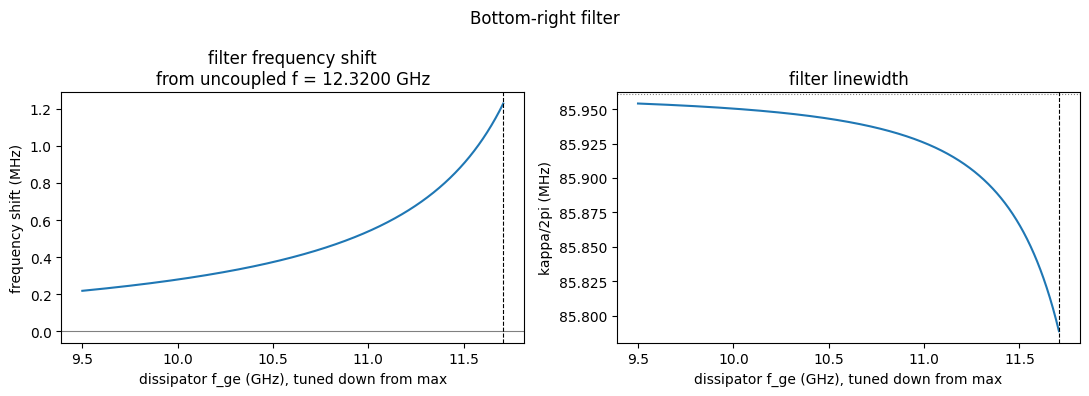

Bottom-right filter: loaded target 12.3200 GHz (bare 13.6043 GHz)
  at f_ge,max = 11.7075 GHz: filter f = 12.3212 GHz (shift +1.23 MHz), kappa/2pi = 85.79 MHz (uncoupled 85.96 MHz)



In [92]:
# bottom-right: measured mode 12.32 GHz (41 MHz linewidth)
filter_vs_dissipator(40.19679, 39.65868, 0.76443, 68.5, 11.7075,
                     1 / (2 * np.pi * 5e-6) / 1e3, "Bottom-right filter", 12.32)